# Gaussian in-family test (d = 16): $D_k = D_{KL}(p\|q_k)$ when the truth is known

Data: drawn from $p^*$ = the max-ent Gaussian of the Scat2 family (`gauss_scat4_test/`, 5 seeds, $N = 10^4$ generated signals per seed).
Model: Scat2 + $L_6$ + Scat4. With infinite data $\theta(\mathrm{Scat4}) = 0$, so **$D_k = 0$ for every Scat4 group**.
With finite data $\theta$ deviates from the truth, and $D_k$ is small but not 0: `pred_H.csv` gives the linear-response
prediction of that finite-data $D_k$ (from the fitted $\theta - \theta^*$). This is the one case where we can check $\hat D_k$ against a known value.

Markers: filled = measured (ESS $\geq 100$ and no drift with $N$, in all seeds), open = lower bound ($D_k \geq \hat D_k$).

In [1]:
import sys
from pathlib import Path
import pandas as pd
sys.path.insert(0, '.')
import plots as P
import matplotlib.pyplot as plt
%matplotlib inline
RES = Path('../gauss_scat4_test/runs/d16/results')
DS = 'gauss4'
df, agg = P.load(DS, RES)
pred = pd.read_csv(RES / 'pred_H.csv')
check = pd.read_csv(RES / 'check.csv')
print(df.seed.unique(), 'seeds |', df.N.iloc[0], 'samples per seed | lam', check.lam.unique())

[900 901 902 903 904] seeds | 10000 samples per seed | lam [1.]


## 1. Is the model right? entropy bound vs exact entropy, $\theta$(Scat2) vs truth
`H_star` = exact entropy of $p^*$ (nats); `Hbound1_minus_Hstar` = MGD entropy bound minus exact; `theta2_rel_err` = relative error of $\theta$(Scat2).

In [2]:
check[['seed', 'lam', 'H_star', 'H_bound_1', 'Hbound1_minus_Hstar', 'Hgen_minus_Hstar', 'theta2_rel_err']].round(4)

,seed,lam,H_star,H_bound_1,Hbound1_minus_Hstar,Hgen_minus_Hstar,theta2_rel_err
0,900,1.0,22.6743,22.6801,0.0057,0.0265,0.0242
1,901,1.0,22.6743,22.6824,0.0081,0.0263,0.0163
2,902,1.0,22.6743,22.6474,-0.0269,0.0264,0.0198
3,903,1.0,22.6743,22.6653,-0.0091,0.0265,0.0205
4,904,1.0,22.6743,22.6689,-0.0054,0.0267,0.0245


## 2. $\hat D_k$ per group, one marker per seed
Scat4 groups: truth with infinite data is 0. Scat2 has a large $D_k$ (removing it leaves almost nothing of the model).

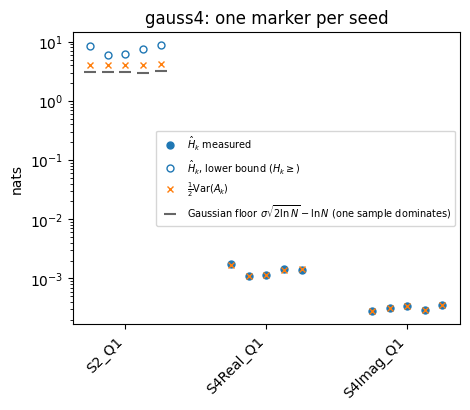

In [3]:
P.bars(agg, title=DS); plt.show()

## 3. Measured $\hat D_k$ vs predicted finite-data $D_k$
Scat4 groups only (their true $\theta$ is 0, so the prediction $\frac{1}{2}\delta\theta^T \mathrm{Cov}\,\delta\theta$ is the finite-data $D_k$).
On the dotted line = the estimator recovers the known value.

In [ ]:
cmp = P.vs_prediction(agg, pred, title=DS); plt.show()
cmp.sort_values(['kind', 'H'], ascending=[True, False]).round(6)

## 4. Per seed

In [ ]:
P.per_seed(df)